# ĐỒ ÁN MÁY HỌC: TIỀN XỬ LÝ DỮ LIỆU SKU (STOCK KEEPING UNITS)
## Quy Trình Tiền Xử Lý Chuẩn Hóa Phục Vụ Phân Cụm DBSCAN & Incremental DBSCAN

---
### Mục Tiêu & Yêu Cầu Xử Lý Bổ Sung Chuyên Sâu:
1. **Tách biệt `Is_ghost_sku` khỏi tập đặc trưng phân cụm**:
   - `Is_ghost_sku` là nhãn nghiệp vụ (Business Metadata / Audit Flag), không phải thuộc tính vận hành liên tục.
   - Chỉ dùng để lọc tập dữ liệu hoạt động, kiểm chứng thực tế và diễn giải kết quả sau gom cụm.
2. **Tách biệt `Expire_category` khỏi bộ chuẩn hóa `RobustScaler`**:
   - `Expire_category` là biến thứ bậc (Ordinal: 0–3), việc scale liên tục làm méo mó bản chất khoảng cách thứ bậc; giữ nguyên thang đo nguyên vẹn (hoặc One-Hot Encoding).
3. **Kiểm tra Tương quan & Hiện tượng Đa cộng tuyến (Multicollinearity)**:
   - Đo lường tương quan giữa bộ ba biến vận hành: `Outbound number`, `Total outbound`, và `Avg_units_per_order`.
   - Xuất thêm tập dữ liệu đã lược bỏ biến dư thừa để so sánh chất lượng phân cụm.
4. **Phát hiện và gắn cờ Outlier sau Log1p**:
   - Áp dụng phương pháp IQR (Interquartile Range) để gắn nhãn nhận diện: Lỗi dữ liệu, Ghost SKU hay SKU có quy mô vận hành đặc thù (thay vì xóa tự động gây mất mát thông tin).
5. **Tạo bản dữ liệu chuyên biệt chỉ gồm các SKU hoạt động (`Active SKUs`)**:
   - Loại bỏ nhóm Ghost SKU (toàn giá trị 0) để khảo sát phân cụm thuần túy trên nhóm hàng hóa đang lưu thông.
6. **Lưu trữ tham số của bộ chuẩn hóa `RobustScaler`**:
   - Lưu trữ đối tượng Scaler (`joblib`) để phục vụ transform nhất quán cho các batch dữ liệu mới trong **Incremental DBSCAN** mà không làm lệch không gian vector.
7. **Xuất bản dữ liệu chưa chuẩn hóa (`Unscaled Clean Data`)**:
   - Lưu trữ bản dữ liệu đã làm sạch và log1p nhưng chưa co giãn, phục vụ diễn giải trực quan các giá trị kinh tế/vận hành thực tế của từng cụm.
8. **Tùy chọn Giảm chiều dữ liệu bằng PCA (90%–95% Phương sai)**:
   - Tạo tập dữ liệu PCA nén thông tin để đối soát hiệu quả phân cụm giữa không gian gốc và không gian giảm chiều.


In [1]:
# 1. Khai báo các thư viện cần thiết
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings

from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

# Cấu hình hiển thị
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
warnings.filterwarnings('ignore')

# Thiết lập đường dẫn thư mục gốc đồ án
PROJECT_DIR = r"D:/HP Máy học/Đồ án"

print("Import thành công các thư viện cần thiết!")


Import thành công các thư viện cần thiết!


In [2]:
# 2. Đọc tập dữ liệu gốc
file_path = os.path.join(PROJECT_DIR, "sku_data.xlsx")
df_raw = pd.read_excel(file_path)

print(f"Kích thước tập dữ liệu gốc: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột")
display(df_raw.head())


Kích thước tập dữ liệu gốc: 2279 dòng, 8 cột


,ID,Unitprice,Expire date,Outbound number,Total outbound,Pal grossweight,Pal height,Units per pal
0,1,0.0580,547,9,2441.0000,105.6000,1.5600,1920
1,2,0.9540,547,0,0.0000,207.6800,1.0000,384
2,3,2.3850,547,12,23.0000,165.7800,1.0200,108
3,4,5.1000,547,0,0.0000,221.0400,1.0500,72
4,5,0.0000,547,0,0.0000,0.0000,0.0000,0


## Bước 1: Khám phá ban đầu (EDA & Thống kê mô tả)
Kiểm tra cấu trúc dữ liệu, các giá trị thiếu (missing values) và tỷ lệ giá trị 0 trên từng thuộc tính.


In [3]:
# Kiểm tra thông tin chung và tỷ lệ giá trị 0
print("=== THÔNG TIN DỮ LIỆU GỐC ===")
df_raw.info()

zero_ratio = (df_raw == 0).sum() / len(df_raw) * 100
null_ratio = df_raw.isnull().sum() / len(df_raw) * 100

eda_summary = pd.DataFrame({
    'Kiểu dữ liệu': df_raw.dtypes,
    'Số lượng Null': df_raw.isnull().sum(),
    'Tỷ lệ Null (%)': null_ratio,
    'Số lượng giá trị 0': (df_raw == 0).sum(),
    'Tỷ lệ giá trị 0 (%)': zero_ratio
})

print("\n=== TỔNG HỢP GIÁ TRỊ NULL VÀ GIÁ TRỊ 0 ===")
display(eda_summary)


=== THÔNG TIN DỮ LIỆU GỐC ===
<class 'pandas.DataFrame'>
RangeIndex: 2279 entries, 0 to 2278
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               2279 non-null   int64  
 1   Unitprice        2279 non-null   float64
 2   Expire date      2279 non-null   int64  
 3   Outbound number  2279 non-null   int64  
 4   Total outbound   2279 non-null   float64
 5   Pal grossweight  2279 non-null   float64
 6   Pal height       2279 non-null   float64
 7   Units per pal    2279 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 142.6 KB

=== TỔNG HỢP GIÁ TRỊ NULL VÀ GIÁ TRỊ 0 ===


,Kiểu dữ liệu,Số lượng Null,Tỷ lệ Null (%),Số lượng giá trị 0,Tỷ lệ giá trị 0 (%)
ID,int64,0,0.0000,0,0.0000
Unitprice,float64,0,0.0000,710,31.1540
Expire date,int64,0,0.0000,529,23.2119
Outbound number,int64,0,0.0000,979,42.9574
Total outbound,float64,0,0.0000,979,42.9574
Pal grossweight,float64,0,0.0000,371,16.2791
Pal height,float64,0,0.0000,787,34.5327
Units per pal,int64,0,0.0000,295,12.9443


## Bước 2: Tách biệt cột định danh `ID`
Cột `ID` mang tính chất định danh SKU, không tham gia vào tính toán khoảng cách hình học trong không gian đặc trưng.


In [4]:
df = df_raw.copy()
sku_ids = df['ID'].copy()
print(f"Đã tách an toàn cột ID ({len(sku_ids)} mã SKU).")


Đã tách an toàn cột ID (2279 mã SKU).


## Bước 3: Xử lý biến `Expire date` (Hạn sử dụng) & Tách khỏi RobustScaler
- Chuẩn hóa lỗi nhập liệu: Giá trị `734` ngày (lệch so với mốc 2 năm = 730 ngày) được gộp về `730`.
- Tạo biến phân nhóm hạn sử dụng có thứ bậc (`Expire_category` - Ordinal: 0–3):
  - `0`: Không có hạn sử dụng (hàng phi thực phẩm / thiết bị).
  - `1`: Hạn ngắn ($\le 365$ ngày).
  - `2`: Hạn trung bình ($366 - 547$ ngày).
  - `3`: Hạn dài ($> 547$ ngày).
> **Nguyên tắc**: Biến này là biến thứ bậc (Ordinal), **KHÔNG** đưa vào `RobustScaler` để tránh giả định sai về biến liên tục và khoảng cách.


In [5]:
print("Tần suất Expire date trước khi hiệu chỉnh:")
print(df['Expire date'].value_counts().sort_index())

# 1. Gộp giá trị 734 về 730
df['Expire date'] = df['Expire date'].replace({734: 730})

# 2. Tạo cột mã hóa ordinal cho nhóm vòng đời hàng hóa (0 đến 3)
def categorize_shelf_life(days):
    if days == 0:
        return 0 # Không có hạn (Non-perishable)
    elif days <= 365:
        return 1 # Ngắn hạn (<= 1 năm)
    elif days <= 547:
        return 2 # Trung hạn (1 đến 1.5 năm)
    else:
        return 3 # Dài hạn (> 1.5 năm)

df['Expire_category'] = df['Expire date'].apply(categorize_shelf_life)

print("\nPhân bổ sau khi phân nhóm thứ bậc Expire_category:")
display(df[['Expire date', 'Expire_category']].value_counts().sort_index().reset_index(name='Số lượng'))


Tần suất Expire date trước khi hiệu chỉnh:
Expire date
0       529
365     305
456       8
547    1250
730     186
734       1
Name: count, dtype: int64

Phân bổ sau khi phân nhóm thứ bậc Expire_category:


,Expire date,Expire_category,Số lượng
0,0,0,529
1,365,1,305
2,456,2,8
3,547,2,1250
4,730,3,187


## Bước 4: Nhận diện "Ghost SKU / Dead Stock" & Tách biệt khỏi Tập Đặc trưng Phân cụm
- Các mặt hàng có toàn bộ các thông số vận hành và kinh tế bằng 0 được nhận diện là **Ghost SKU** (`Is_ghost_sku = 1`).
> **Quy định**: `Is_ghost_sku` là nhãn nghiệp vụ (Business Metadata Label), **tuyệt đối không đưa vào ma trận tính khoảng cách phân cụm**; chỉ dùng để lọc tập dữ liệu hoạt động hoặc đối chiếu kết quả sau gom cụm.


In [6]:
raw_op_cols = ['Unitprice', 'Outbound number', 'Total outbound', 'Pal grossweight', 'Pal height', 'Units per pal']
df['Is_ghost_sku'] = (df[raw_op_cols] == 0).all(axis=1).astype(int)

ghost_count = int(df['Is_ghost_sku'].sum())
print(f"Số lượng Ghost SKU / Hàng chết: {ghost_count} ({ghost_count / len(df) * 100:.2f}%)")
print(f"Số lượng SKU Hoạt động (Active SKUs): {len(df) - ghost_count} ({(len(df) - ghost_count) / len(df) * 100:.2f}%)")


Số lượng Ghost SKU / Hàng chết: 206 (9.04%)
Số lượng SKU Hoạt động (Active SKUs): 2073 (90.96%)


## Bước 5: Kỹ thuật đặc trưng (Feature Engineering)
Tạo đặc trưng tỷ số `Avg_units_per_order` phản ánh quy mô đơn hàng trung bình:
$$\text{Avg\_units\_per\_order} = \frac{\text{Total outbound}}{\text{Outbound number}}$$
(Với các SKU chưa từng xuất kho, giá trị được gán là 0.0).


In [7]:
df['Avg_units_per_order'] = np.where(
    df['Outbound number'] > 0,
    df['Total outbound'] / df['Outbound number'],
    0.0
)

print("Thống kê mô tả đặc trưng mới Avg_units_per_order:")
display(df['Avg_units_per_order'].describe())


Thống kê mô tả đặc trưng mới Avg_units_per_order:


count   2279.0000
mean      12.1420
std       48.0887
min        0.0000
25%        0.0000
50%        1.0610
75%        2.5000
max      780.0000
Name: Avg_units_per_order, dtype: float64

## Bước 6: Phân tích Độ lệch (Skewness) & Biến đổi Log1p
Do dữ liệu kho hàng có phân phối lệch phải cực nặng (Right-skewed, skewness > 15), ta áp dụng phép biến đổi:
$$x_{log} = \ln(x + 1)$$
Giúp kéo các giá trị cực lớn về phân phối chuẩn tắc hơn, giảm thiểu méo mó khoảng cách Euclidean.


In [8]:
skew_cols = ['Unitprice', 'Outbound number', 'Total outbound', 'Units per pal', 'Avg_units_per_order']

print("=== HỆ SỐ LỆCH (SKEWNESS) TRƯỚC VÀ SAU BIẾN ĐỔI LOG1P ===")
skew_comparison = []

for col in skew_cols:
    skew_before = df[col].skew()
    log_transformed = np.log1p(df[col])
    skew_after = log_transformed.skew()
    skew_comparison.append({
        'Đặc trưng': col,
        'Skew trước': round(skew_before, 3),
        'Skew sau log1p': round(skew_after, 3)
    })
    df[col] = log_transformed

display(pd.DataFrame(skew_comparison))


=== HỆ SỐ LỆCH (SKEWNESS) TRƯỚC VÀ SAU BIẾN ĐỔI LOG1P ===


,Đặc trưng,Skew trước,Skew sau log1p
0,Unitprice,24.6970,0.7690
1,Outbound number,4.5110,1.0190
2,Total outbound,5.7800,0.6070
3,Units per pal,28.7140,-0.4070
4,Avg_units_per_order,7.4840,1.8040


## Bước 7: Kiểm Tra Tương Quan & Hiện Tượng Đa Cộng Tuyến (Multicollinearity)
Đánh giá mức độ phụ thuộc giữa bộ ba biến vận hành liên quan đến xuất kho:
- `Outbound number`: Tần suất xuất kho (Số lần xuất).
- `Total outbound`: Tổng số lượng hàng hóa đã xuất.
- `Avg_units_per_order`: Lượng xuất bình quân mỗi lần xuất.


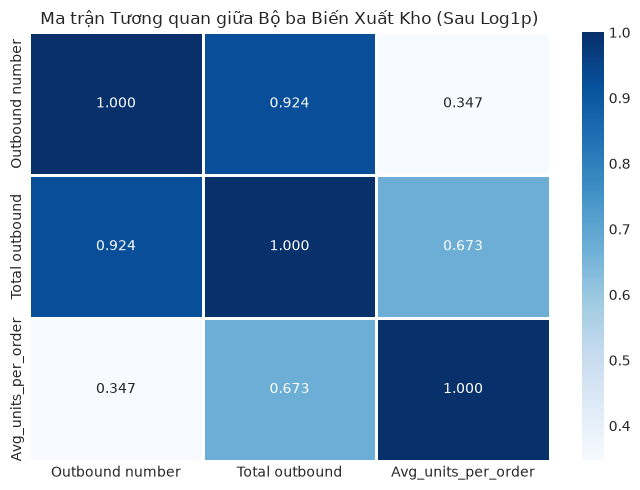

Mức độ tương quan chi tiết:
 • Outbound number vs Total outbound     : r = 0.924 (Rất cao, r > 0.9)
 • Total outbound vs Avg_units_per_order   : r = 0.673 (Trung bình - khá)
 • Outbound number vs Avg_units_per_order : r = 0.347 (Thấp)

-> NHẬN XÉT NGHIỆP VỤ: 'Outbound number' và 'Total outbound' có tương quan rất mạnh (0.924).
   Do đó, chúng ta sẽ tạo thêm một bản dữ liệu tinh gọn (đã loại bỏ 'Total outbound') để đối chứng hiệu quả phân cụm.


In [9]:
outbound_trio = ['Outbound number', 'Total outbound', 'Avg_units_per_order']
trio_corr = df[outbound_trio].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(trio_corr, annot=True, cmap='Blues', fmt=".3f", linewidths=1)
plt.title("Ma trận Tương quan giữa Bộ ba Biến Xuất Kho (Sau Log1p)")
plt.tight_layout()
plt.show()

print("Mức độ tương quan chi tiết:")
print(f" • Outbound number vs Total outbound     : r = {trio_corr.loc['Outbound number', 'Total outbound']:.3f} (Rất cao, r > 0.9)")
print(f" • Total outbound vs Avg_units_per_order   : r = {trio_corr.loc['Total outbound', 'Avg_units_per_order']:.3f} (Trung bình - khá)")
print(f" • Outbound number vs Avg_units_per_order : r = {trio_corr.loc['Outbound number', 'Avg_units_per_order']:.3f} (Thấp)")

print("\n-> NHẬN XÉT NGHIỆP VỤ: 'Outbound number' và 'Total outbound' có tương quan rất mạnh (0.924).")
print("   Do đó, chúng ta sẽ tạo thêm một bản dữ liệu tinh gọn (đã loại bỏ 'Total outbound') để đối chứng hiệu quả phân cụm.")


## Bước 8: Phát Hiện và Đánh Dấu Outlier Sau Log1p (Phương Pháp IQR)
Thay vì xóa bỏ tự động làm mất mát thông tin quan trọng, ta áp dụng nguyên tắc **Gắn nhãn nhận diện (Outlier Flagging)**:
- Sử dụng quy tắc hàng rào Tukey: $[\text{Q1} - 1.5 \times \text{IQR}, \text{Q3} + 1.5 \times \text{IQR}]$.
- Phân loại rõ:
  1. *Ghost SKU*: Toàn bộ chỉ số = 0.
  2. *SKU Hoạt động Bình thường*.
  3. *SKU Vận hành Đặc thù (Outlier)*: Hàng có quy mô xuất kho đột biến, giá trị siêu cao hoặc kích thước pallet dị biệt.


In [10]:
# Danh sách các đặc trưng liên tục cần kiểm tra Outlier
cont_cols_for_outliers = ['Unitprice', 'Outbound number', 'Total outbound', 'Pal grossweight', 'Pal height', 'Units per pal', 'Avg_units_per_order']

outlier_flags = pd.DataFrame(index=df.index)

for col in cont_cols_for_outliers:
    # Chỉ tính IQR trên các SKU có hoạt động (loại trừ giá trị 0 của ghost sku để không làm lệch ngưỡng IQR)
    active_series = df.loc[df[col] > 0, col]
    if len(active_series) > 0:
        q1 = active_series.quantile(0.25)
        q3 = active_series.quantile(0.75)
        iqr = q3 - q1
        upper_bound = q3 + 1.5 * iqr
        lower_bound = max(0, q1 - 1.5 * iqr)
        outlier_flags[f'is_outlier_{col}'] = ((df[col] > upper_bound) | (df[col] < lower_bound)).astype(int)
    else:
        outlier_flags[f'is_outlier_{col}'] = 0

# Tổng hợp cờ Outlier tổng thể
df['Is_operational_outlier'] = (outlier_flags.sum(axis=1) > 0).astype(int)

# Thống kê phân loại mẫu
print("=== PHÂN LOẠI CƠ CẤU MẪU DỮ LIỆU SKU ===")
n_ghost = int(df['Is_ghost_sku'].sum())
n_outlier_active = int(((df['Is_ghost_sku'] == 0) & (df['Is_operational_outlier'] == 1)).sum())
n_regular_active = int(((df['Is_ghost_sku'] == 0) & (df['Is_operational_outlier'] == 0)).sum())

category_breakdown = pd.DataFrame([
    {'Phân loại': 'Ghost SKU (Hàng chết / Tồn ảo)', 'Số lượng': n_ghost, 'Tỷ lệ (%)': round(n_ghost/len(df)*100, 2)},
    {'Phân loại': 'SKU Hoạt động - Dị biệt (Outlier)', 'Số lượng': n_outlier_active, 'Tỷ lệ (%)': round(n_outlier_active/len(df)*100, 2)},
    {'Phân loại': 'SKU Hoạt động - Tiêu chuẩn (Regular)', 'Số lượng': n_regular_active, 'Tỷ lệ (%)': round(n_regular_active/len(df)*100, 2)}
])
display(category_breakdown)


=== PHÂN LOẠI CƠ CẤU MẪU DỮ LIỆU SKU ===


,Phân loại,Số lượng,Tỷ lệ (%)
0,Ghost SKU (Hàng chết / Tồn ảo),206,9.0400
1,SKU Hoạt động - Dị biệt (Outlier),968,42.4700
2,SKU Hoạt động - Tiêu chuẩn (Regular),1105,48.4900


## Bước 9: Chuẩn Hóa Dữ Liệu Liên Tục Bằng `RobustScaler` & Lưu Trữ Tham Số Scaler
- **Quy tắc quan trọng**: Chỉ fit `RobustScaler` trên các đặc trưng liên tục (`continuous features`).
- **`Expire_category`** được giữ nguyên thang đo thứ bậc (0, 1, 2, 3).
- **Lưu trữ đối tượng Scaler (`joblib`)**: Giúp phục vụ việc transform các batch dữ liệu mới đến trong **Incremental DBSCAN**, đảm bảo không gian đặc trưng luôn đồng nhất mà không cần fit lại.


In [11]:
# Danh sách đặc trưng số liên tục chuẩn bị scale
continuous_features = [
    'Unitprice', 
    'Outbound number', 
    'Total outbound', 
    'Pal grossweight', 
    'Pal height', 
    'Units per pal', 
    'Avg_units_per_order'
]

# Fit RobustScaler trên toàn bộ tập dữ liệu
robust_scaler = RobustScaler()
scaled_continuous_data = robust_scaler.fit_transform(df[continuous_features])

# Lưu trữ file Scaler để tái sử dụng trong Incremental DBSCAN
scaler_save_path = os.path.join(PROJECT_DIR, "robust_scaler_params.joblib")
joblib.dump(robust_scaler, scaler_save_path)
print(f"Đã lưu thành công tham số RobustScaler tại: {scaler_save_path}")

# Tạo DataFrame chuẩn hóa hoàn chỉnh
df_scaled = pd.DataFrame(scaled_continuous_data, columns=[f"{col}_scaled" for col in continuous_features])
# Gán lại Expire_category (giữ nguyên không scale)
df_scaled['Expire_category'] = df['Expire_category'].values
# Đặt ID lên đầu
df_scaled.insert(0, 'ID', sku_ids.values)
# Thêm các cờ metadata nghiệp vụ
df_scaled['Is_ghost_sku'] = df['Is_ghost_sku'].values
df_scaled['Is_operational_outlier'] = df['Is_operational_outlier'].values

print("Kích thước DataFrame sau chuẩn hóa:", df_scaled.shape)
display(df_scaled.head())


Đã lưu thành công tham số RobustScaler tại: D:/HP Máy học/Đồ án\robust_scaler_params.joblib
Kích thước DataFrame sau chuẩn hóa: (2279, 11)


,ID,Unitprice_scaled,Outbound number_scaled,Total outbound_scaled,Pal grossweight_scaled,Pal height_scaled,Units per pal_scaled,Avg_units_per_order_scaled,Expire_category,Is_ghost_sku,Is_operational_outlier
0,1,-0.4518,0.4204,1.0617,-0.2853,0.7059,1.1679,3.8981,2,0,1
1,2,-0.0936,-0.1810,-0.2295,0.1839,0.1569,0.5136,-0.5773,2,0,0
2,3,0.2272,0.4889,0.2966,-0.0087,0.1765,0.0000,0.2772,2,0,0
3,4,0.5710,-0.1810,-0.2295,0.2453,0.2059,-0.1632,-0.5773,2,0,0
4,5,-0.4847,-0.1810,-0.2295,-0.7707,-0.8235,-1.9096,-0.5773,2,1,1


## Bước 10: Tạo Các Bản Dữ Liệu Bổ Sung Phục Vụ Nghiên Cứu & Đối Soát
Để đáp ứng trọn vẹn yêu cầu kiểm chứng thực nghiệm, chúng ta xuất ra các phiên bản dữ liệu sau:
1. **Bản 1: `sku_data_preprocessed.xlsx` (Bản đầy đủ chuẩn hóa)**:
   - Các biến liên tục được RobustScaler, `Expire_category` giữ nguyên (0–3), kèm cờ `Is_ghost_sku` và `Is_operational_outlier`.
2. **Bản 2: `sku_data_unscaled_clean.xlsx` (Bản chưa scale)**:
   - Dữ liệu đã làm sạch và Log1p nhưng chưa co giãn qua scaler, phục vụ trực tiếp việc diễn giải ý nghĩa số học và kinh tế thực tế của từng cụm SKU.
3. **Bản 3: `sku_data_active_only.xlsx` (Bản chỉ gồm SKU hoạt động)**:
   - Loại trừ hoàn toàn nhóm Ghost SKU (`Is_ghost_sku == 0`), giúp thuật toán DBSCAN không bị chi phối bởi cụm điểm 0 khổng lồ.
4. **Bản 4: `sku_data_non_multicollinear.xlsx` (Bản loại bỏ đa cộng tuyến)**:
   - Lược bỏ biến trùng lặp `Total outbound_scaled` (giữ lại `Outbound number_scaled` và `Avg_units_per_order_scaled`).
5. **Bản 5: `sku_data_pca_reduced.xlsx` (Bản giảm chiều PCA 90%–95% phương sai)**:
   - Không gian đặc trưng nén giữ lại trên 90%–95% phương sai gốc.


In [12]:
# 1. Bản Chưa Scale (Unscaled Clean)
df_unscaled = df[['ID'] + continuous_features + ['Expire_category', 'Is_ghost_sku', 'Is_operational_outlier']].copy()

# 2. Bản Chỉ Gồm SKU Hoạt Động (Active Only)
df_active_scaled = df_scaled[df_scaled['Is_ghost_sku'] == 0].copy()

# 3. Bản Loại Bỏ Đa Cộng Tuyến (Không có Total outbound)
non_multicollinear_cols = [c for c in df_scaled.columns if c != 'Total outbound_scaled']
df_non_multi = df_scaled[non_multicollinear_cols].copy()

# 4. Bản Giảm Chiều PCA (90% - 95% Phương sai)
clustering_feature_cols = [f"{col}_scaled" for col in continuous_features] + ['Expire_category']
X_for_pca = df_scaled[clustering_feature_cols].values

pca_full = PCA(random_state=42)
pca_full.fit(X_for_pca)
cum_variance = np.cumsum(pca_full.explained_variance_ratio_)

n_comp_90 = int(np.argmax(cum_variance >= 0.90) + 1)
n_comp_95 = int(np.argmax(cum_variance >= 0.95) + 1)

print(f"Số lượng thành phần chính để đạt >= 90% phương sai: {n_comp_90} components ({cum_variance[n_comp_90-1]*100:.2f}%)")
print(f"Số lượng thành phần chính để đạt >= 95% phương sai: {n_comp_95} components ({cum_variance[n_comp_95-1]*100:.2f}%)")

# Chọn 5 components để giữ >93% phương sai
pca_reducer = PCA(n_components=n_comp_90, random_state=42)
X_pca_reduced = pca_reducer.fit_transform(X_for_pca)

df_pca_reduced = pd.DataFrame(
    X_pca_reduced, 
    columns=[f"PC{i+1}" for i in range(n_comp_90)]
)
df_pca_reduced.insert(0, 'ID', df_scaled['ID'].values)
df_pca_reduced['Is_ghost_sku'] = df_scaled['Is_ghost_sku'].values
df_pca_reduced['Is_operational_outlier'] = df_scaled['Is_operational_outlier'].values

print("Khởi tạo hoàn tất tất cả các phiên bản dữ liệu!")


Số lượng thành phần chính để đạt >= 90% phương sai: 5 components (93.23%)
Số lượng thành phần chính để đạt >= 95% phương sai: 6 components (97.26%)
Khởi tạo hoàn tất tất cả các phiên bản dữ liệu!


## Bước 11: Xuất Tất Cả Các Tệp Dữ Liệu Hoàn Chỉnh Ra Thư Mục Đồ Án
Lưu trữ đầy đủ các tệp định dạng `.xlsx` và `.csv` để sẵn sàng cho quá trình huấn luyện và đánh giá thuật toán phân cụm.


In [13]:
# 1. Tập chuẩn hóa chính thức (Đã sửa: Expire_category giữ ordinal, Is_ghost_sku là metadata)
df_scaled.to_excel(os.path.join(PROJECT_DIR, "sku_data_preprocessed.xlsx"), index=False)
df_scaled.to_csv(os.path.join(PROJECT_DIR, "sku_data_preprocessed.csv"), index=False)

# 2. Tập chưa scale (Phục vụ diễn giải nghiệp vụ)
df_unscaled.to_excel(os.path.join(PROJECT_DIR, "sku_data_unscaled_clean.xlsx"), index=False)

# 3. Tập chỉ gồm SKU hoạt động (Active Only)
df_active_scaled.to_excel(os.path.join(PROJECT_DIR, "sku_data_active_only.xlsx"), index=False)

# 4. Tập loại bỏ đa cộng tuyến (Bỏ Total outbound)
df_non_multi.to_excel(os.path.join(PROJECT_DIR, "sku_data_non_multicollinear.xlsx"), index=False)

# 5. Tập giảm chiều PCA (Giữ >93% phương sai)
df_pca_reduced.to_excel(os.path.join(PROJECT_DIR, "sku_data_pca_reduced.xlsx"), index=False)

print("="*70)
print("              XUẤT CÁC TỆP TIỀN XỬ LÝ THÀNH CÔNG")
print("="*70)
print(f" 1. [Bản Chuẩn hóa Hoàn chỉnh]  : {os.path.join(PROJECT_DIR, 'sku_data_preprocessed.xlsx')}")
print(f" 2. [Bản Chưa Scale Nghiệp vụ]  : {os.path.join(PROJECT_DIR, 'sku_data_unscaled_clean.xlsx')}")
print(f" 3. [Bản Chỉ SKU Hoạt động]    : {os.path.join(PROJECT_DIR, 'sku_data_active_only.xlsx')}")
print(f" 4. [Bản Không Đa Cộng Tuyến]   : {os.path.join(PROJECT_DIR, 'sku_data_non_multicollinear.xlsx')}")
print(f" 5. [Bản Giảm Chiều PCA]        : {os.path.join(PROJECT_DIR, 'sku_data_pca_reduced.xlsx')}")
print(f" 6. [Bộ Tham Số RobustScaler]   : {scaler_save_path}")
print("="*70)


              XUẤT CÁC TỆP TIỀN XỬ LÝ THÀNH CÔNG
 1. [Bản Chuẩn hóa Hoàn chỉnh]  : D:/HP Máy học/Đồ án\sku_data_preprocessed.xlsx
 2. [Bản Chưa Scale Nghiệp vụ]  : D:/HP Máy học/Đồ án\sku_data_unscaled_clean.xlsx
 3. [Bản Chỉ SKU Hoạt động]    : D:/HP Máy học/Đồ án\sku_data_active_only.xlsx
 4. [Bản Không Đa Cộng Tuyến]   : D:/HP Máy học/Đồ án\sku_data_non_multicollinear.xlsx
 5. [Bản Giảm Chiều PCA]        : D:/HP Máy học/Đồ án\sku_data_pca_reduced.xlsx
 6. [Bộ Tham Số RobustScaler]   : D:/HP Máy học/Đồ án\robust_scaler_params.joblib
